<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# DBSCAN and Agglomerative Clustering - Solution

---

### About
Understand and use DBSCAN and agglomerative clustering techiniques.

### Learning Objectives
- Describe the effect of epsilon and min_points on DBSCAN.
- Identify advantages and disadvantages of DBSCAN.
- Implement DBSCAN using `scikit-learn`.
- Describe the agglomerative clustering technique.
- Identify advantages and disadvantages of agglomerative clustering.
- Implement agglomerative clustering using `scikit-learn`.

### Notebook Guide
- Imports
- Load Data
- Fit a DBSCAN model
- Agglomerative (Hierarchical) Clustering
- Conclusions and Takeaways

# Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn import metrics
from scipy.cluster.hierarchy import dendrogram

# Load data
---

In [2]:
names = [
    'area', 'perimeter', 'compactness',
    'kern_len', 'kern_width', 'asymmetry',
    'groove_width', 'variety'
]
seeds = pd.read_csv('../data/seeds_dataset.txt', sep=r'\s+', names=names)
seeds.head()

,area,perimeter,compactness,kern_len,kern_width,asymmetry,groove_width,variety
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


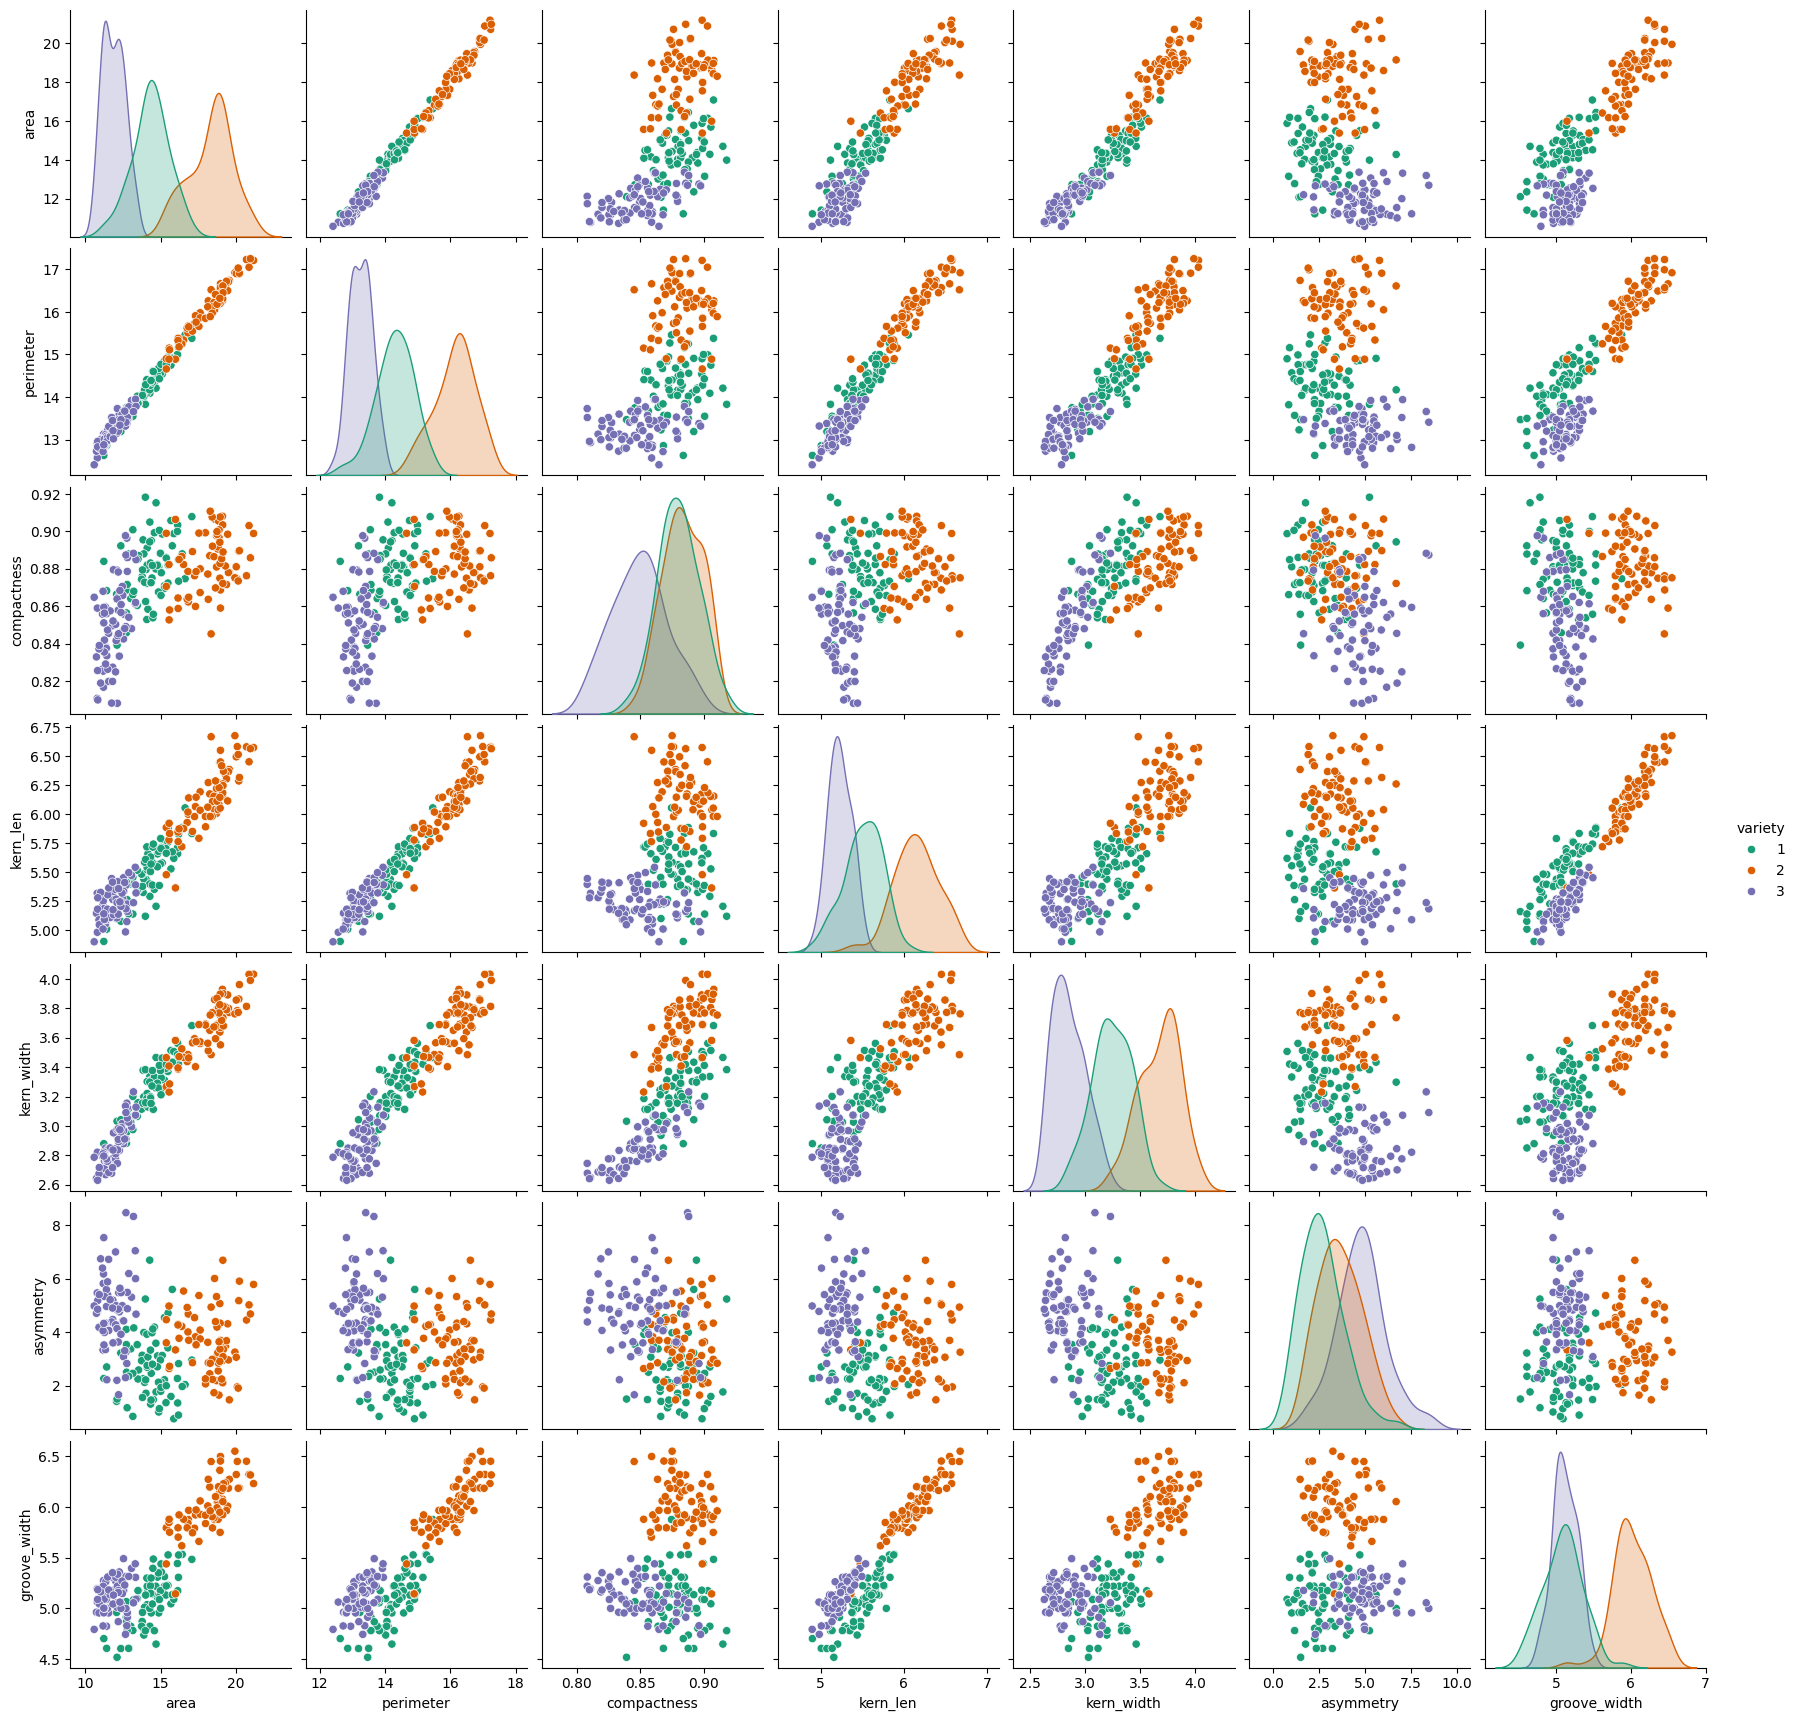

In [3]:
# Some fast EDA
sns.pairplot(seeds, hue='variety', palette='Dark2');

In [4]:
# Let's use ONLY kernel width and groove width to do our clustering.
# (YOU) make me an X and standard scale it!
X = seeds[['kern_width', 'groove_width']]
Z = StandardScaler().fit_transform(X)

# Fit a DBSCAN model
---

In [5]:
# Let's fit a DBSCAN with epsilon = 0.3 and n = 7
db = DBSCAN(eps=0.3, min_samples=7)
db.fit(Z)

,"eps eps: float, default=0.5The maximum distance between two samples for one to be consideredas in the neighborhood of the other. This is not a maximum boundon the distances of points within a cluster. This is the mostimportant DBSCAN parameter to choose appropriately for your data setand distance function. Smaller values generally lead to more clusters.",0.3
,"min_samples min_samples: int, default=5The number of samples (or total weight) in a neighborhood for a point tobe considered as a core point. This includes the point itself. If`min_samples` is set to a higher value, DBSCAN will find denser clusters,whereas if it is set to a lower value, the found clusters will be moresparse.",7
,"metric metric: str, or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array. If metric is a string or callable, it must be one ofthe options allowed by :func:`sklearn.metrics.pairwise_distances` forits metric parameter.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors for DBSCAN... versionadded:: 0.17 metric *precomputed* to accept precomputed sparse matrix.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function... versionadded:: 0.19",None
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'The algorithm to be used by the NearestNeighbors moduleto compute pointwise distances and find nearest neighbors.'auto' will attempt to decide the most appropriate algorithmbased on the values passed to :meth:`fit` method.See :class:`~sklearn.neighbors.NearestNeighbors` documentation fordetails.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or cKDTree. This can affect the speedof the construction and query, as well as the memory requiredto store the tree. The optimal value dependson the nature of the problem.",30
,"p p: float, default=NoneThe power of the Minkowski metric to be used to calculate distancebetween points. If None, then ``p=2`` (equivalent to the Euclideandistance). When p=1, this is equivalent to Manhattan distance.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
"components_ components_: ndarray of shape (n_core_samples, n_features)Copy of each core sample found by training.","ndarray[float64](152, 2)","[[ 0.14,-0.38], [ 0.2 ,-0.92], [ 0.14,-0.92], ..., [-0.07,-0.72], [-1.12,-0.74], [-0.76,-0.7 ]]"
"core_sample_indices_ core_sample_indices_: ndarray of shape (n_core_samples,)Indices of core samples.","ndarray[int64](152,)","[ 0, 1, 5,...,207,208,209]"


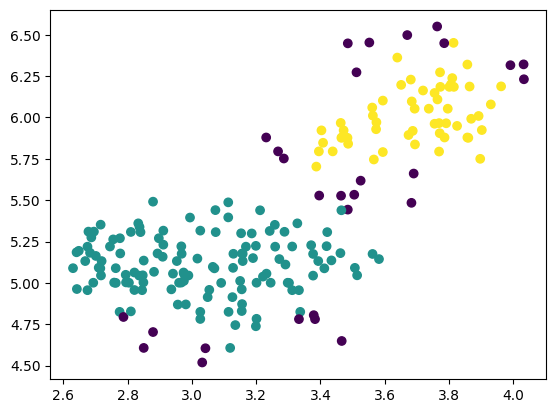

In [6]:
# Let's plot our clusters on the original data scale and color them in.
plt.scatter(X.kern_width, X.groove_width, c=db.labels_)

## Model Evaluation: Silhouette Score
---

Recall the formula for silhouette score:

### $s_i = \frac{b_i - a_i}{max\{a_i, b_i\}}$

Where:
- $a_i$ = Cohesion: Average distance of points within clusters
- $b_i$ = Separation: Average distance from point $x_i$ to all points in the next nearest cluster.

In the cell below, use the `silhouette_score` function from `scikit-learn` to evaluate our `DBSCAN` model.

In [7]:
# What's the silhouette score of our DBSCAN(0.3, 7) cluster?

metrics.silhouette_score(Z, db.labels_)

0.4331166977120715

-0.4872295806218845

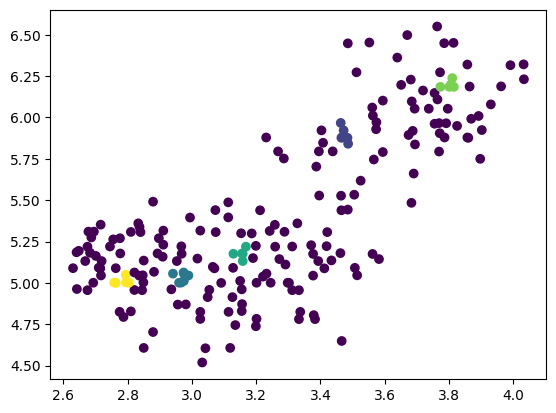

In [8]:
# Put everything in one cell here and rapidly iterate epsilon and cluster

db = DBSCAN(eps=0.1, min_samples=5)
db.fit(Z)
plt.scatter(X.kern_width, X.groove_width, c=db.labels_)
metrics.silhouette_score(Z, db.labels_)

In [9]:
# Painful, but you *could* brute force the params

e_vec = np.linspace(0.01, 0.7, 100)
n_vec = np.arange(1, 15)
res = []

for e in e_vec:
    for n in n_vec:
        cl = DBSCAN(eps=e, min_samples=n)
        cl.fit(Z)
        lbls = pd.Series(cl.labels_)
        if lbls.nunique() <= 1:
            continue
            
        sil = metrics.silhouette_score(Z, cl.labels_)
        res.append((e, n, sil))

In [10]:
df_res = pd.DataFrame(res, columns=['e', 'n', 'sil'])

In [11]:
df_res.sort_values('sil', ascending=False)

,e,n,sil
684,0.539697,14,0.615489
683,0.539697,13,0.615489
663,0.504848,11,0.568014
644,0.483939,10,0.539827
631,0.470000,10,0.539827
...,...,...,...
10,0.037879,2,-0.550148
7,0.030909,2,-0.552945
26,0.072727,3,-0.554083
5,0.023939,2,-0.602787


0.6154893353164566

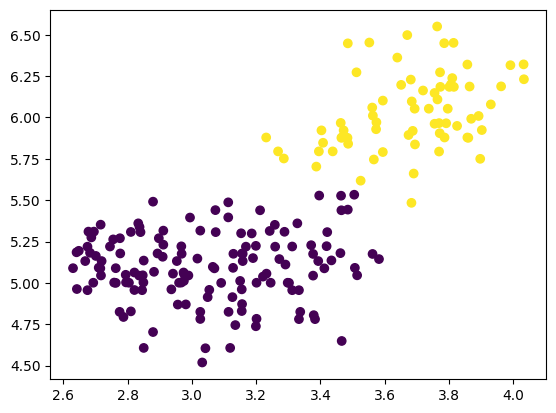

In [12]:
db = DBSCAN(eps=0.54, min_samples=14)
db.fit(Z)
plt.scatter(X.kern_width, X.groove_width, c=db.labels_)
metrics.silhouette_score(Z, db.labels_)

---

To the slides!

---

# Agglomerative (Hierarchical) Clustering
---
**Hierarchical clustering** is a technique in which we join or split successive clusters. We can plot such a models' **dendrogram** if we want, too!

In [13]:
# Let's fit an agglomerative clusterer with 3 clusters.
agglom = AgglomerativeClustering(3)
agglom.fit(Z)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",3
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" and ""l2"" are accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and metric is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'ward'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",None
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False
Name,Type,Value
"children_ children_: array-like of shape (n_samples-1, 2)The children of each non-leaf node. Values less than `n_samples`correspond to leaves of the tree which are the original samples.A node `i` greater than or equal to `n_samples

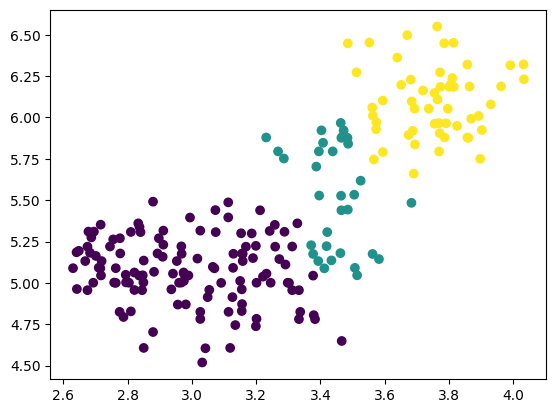

In [14]:
# Let's see it visually
plt.scatter(X.kern_width, X.groove_width, c=agglom.labels_);

In [15]:
# Silhouette?
metrics.silhouette_score(Z, agglom.labels_)

0.43908974634556064

In [16]:
# TAKEN FROM SCIKIT-LEARN DOCS HERE!!
# https://scikit-learn.org/stable/auto_examples/cluster/plot_agglomerative_dendrogram.html

def plot_dendrogram(model, **kwargs):
    # Create linkage matrix and then plot the dendrogram

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    # Plot the corresponding dendrogram
    dendrogram(linkage_matrix, **kwargs)

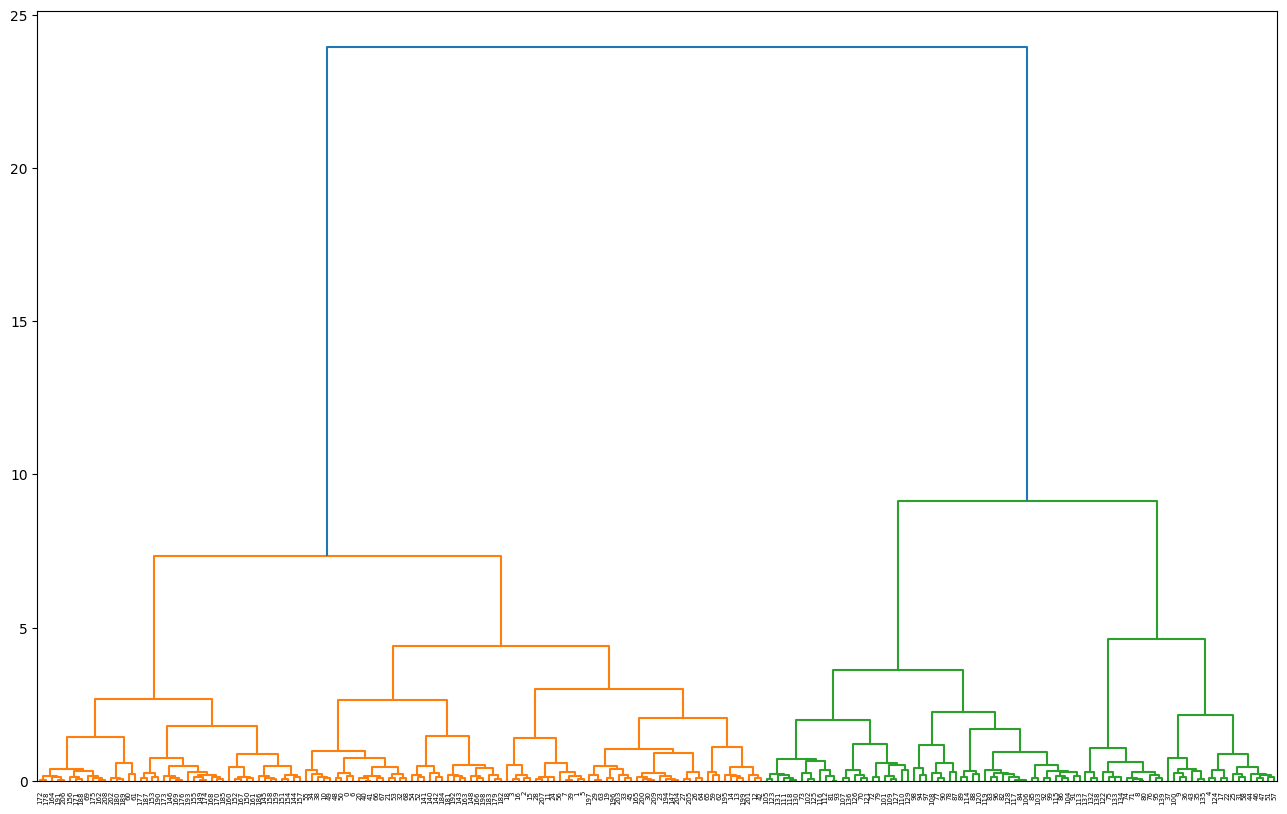

In [17]:
# These arguments are required to fit the whole tree. We can't plot the whole tree
# without computing it!
agglom = AgglomerativeClustering(n_clusters=None, distance_threshold=0)
agglom.fit(Z)

plt.figure(figsize=(16, 10))
plot_dendrogram(agglom)

## DBSCAN conclusions
* DBSCAN is an interesting one in that it clusters based on the density of clusters...
* However, it comes at the cost of needing TWO (2!) tuning parameters.
* DBSCAN can also help us detect **outliers**.

## Agglomerative clustering conclusions
* Distance-based clustering algo that starts with every observation separate and successively joins clusters.
* Allows us to see the "path" of joins based similarity.
* Can plot nice **dendrograms**, although not always as useful as you'd think.

# Conclusions and Takeaways
---
Clustering is one of the two most common use cases for **unsupervised learning** (the other being dimensionality reduction). 

* It's used to segment your data into groups where members of one cluster are most similar to eachother than they are to observations in other groups.
* This process is totally independent of a $y$-variable! It only uses your $x$s.
* Almost all of these techniques rely on computing **distance metrics** between points, so **scaling** is important!
* There are many, many clustering algorithms out there and in sklearn! [Here are the ones we can enjoy via sklearn](https://scikit-learn.org/stable/modules/clustering.html#clustering).
* $k$-Means is probably the most well-known and therefore most commonly used.
* Although [k-medoids clustering](https://en.wikipedia.org/wiki/K-medoids) is a popular choice too, and it's not even contained in `scikit-learn`! It is very similar to k-means, though.